In [1]:
import sys

print("===================================")
print("MLOps Assignment - Environment Check")
print("===================================")

print("Python Version:", sys.version)
print("Python Executable:", sys.executable)

MLOps Assignment - Environment Check
Python Version: 3.11.6 (tags/v3.11.6:8b6ee5b, Oct  2 2023, 14:57:12) [MSC v.1935 64 bit (AMD64)]
Python Executable: c:\Users\ilama\Documents\MLOps_Assignment\mlops_env\Scripts\python.exe


In [2]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

print("All libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully!


In [ ]:


iris = load_iris(as_frame=True)


df = iris.frame.copy()

print("Iris dataset loaded successfully!")
print("Dataset shape:", df.shape)

Iris dataset loaded successfully!
Dataset shape: (150, 5)


In [ ]:


df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [5]:
# Dataset information

print("Dataset Information:")
print("--------------------")

print("Number of samples:", df.shape[0])
print("Number of features:", df.shape[1] - 1)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["target"].value_counts().sort_index())

Dataset Information:
--------------------
Number of samples: 150
Number of features: 4

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Target distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64


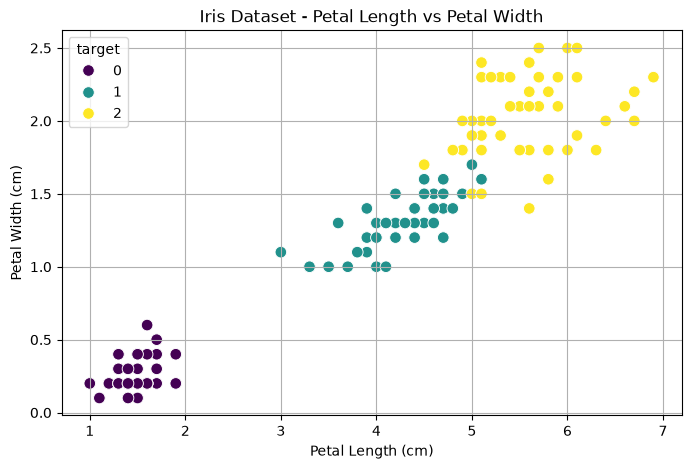

In [6]:
# Visualize Iris flower classes

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="target",
    palette="viridis",
    s=70
)

plt.title("Iris Dataset - Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.grid(True)

plt.show()

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

Training samples: 120
Testing samples: 30

Random Forest model trained successfully!

========== MODEL EVALUATION ==========
Accuracy  : 0.9333
Precision : 0.9333
Recall    : 0.9333
F1-score  : 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



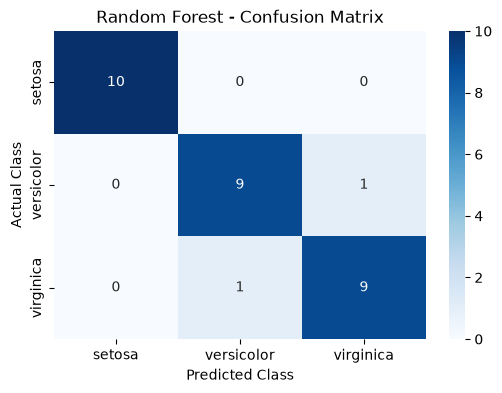

Dataset saved successfully!


In [9]:
# STEP 4: Train-Test Split

X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# STEP 5: Train Random Forest Model

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

print("\nRandom Forest model trained successfully!")


# STEP 6: Predictions

y_pred = model.predict(X_test)


# STEP 7: Model Evaluation

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("\n========== MODEL EVALUATION ==========")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=iris.target_names
))


# STEP 8: Confusion Matrix

plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


# STEP 9: Save Dataset

from pathlib import Path

Path("data/raw").mkdir(parents=True, exist_ok=True)
df.to_csv("data/raw/iris.csv", index=False)

print("Dataset saved successfully!")

In [10]:
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "raw"
data_path.mkdir(parents=True, exist_ok=True)

df.to_csv(data_path / "iris.csv", index=False)

print("Dataset saved successfully!")
print("File location:", data_path / "iris.csv")
print("File exists:", (data_path / "iris.csv").exists())

Dataset saved successfully!
File location: c:\Users\ilama\Documents\MLOps_Assignment\data\raw\iris.csv
File exists: True
